# Results: Drawing Quality

Computes every number, table and figure of Section *Results / Drawing Quality*, and nothing else.

**Design.** 220 lattices that every algorithm can draw $\times$ 8 algorithms, scored by 14 metrics in $[0,1]$.
All comparisons use within-lattice ranks (1 = best, average ranks for ties); scores are rounded to $10^{-9}$ before ranking.

Outputs: `figures/ranks.{pdf,png}`, `figures/distributivity.{pdf,png}`, `tables/context.tex`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import FancyBboxPatch
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
sys.path.insert(0, str(ROOT))
from lattice_metrics import load_layout

OUT = ROOT / 'analysis'
FIG, TAB = OUT / 'figures', OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.precision', 3)
ALPHA = 0.05

METRICS = {   # column -> (short, family), in paper order
    'edge_crossing':          ('EC', 'Crossings'),
    'crossing_angle':         ('CA', 'Crossings'),
    'layer_consistency':      ('LC', 'Layering'),
    'vertical_axis_balance':  ('SY', 'Layering'),
    'slope_verticality':      ('FE', 'Slopes'),
    'slope_economy':          ('SE', 'Slopes'),
    'slope_parallelism':      ('SP', 'Slopes'),
    'edge_length_uniformity': ('EH', 'Slopes'),
    'slope_standard':         ('SC', 'Slopes'),
    'visual_chain_linearity': ('CL', 'Slopes'),
    'node_edge_conflict':     ('NE', 'Clearance'),
    'node_node_conflict':     ('NN', 'Clearance'),
    'edge_edge_conflict':     ('EE', 'Clearance'),
    'nested_suitability':     ('NS', 'Clearance'),
}
MS = [v[0] for v in METRICS.values()]
FAMILY = {v[0]: v[1] for v in METRICS.values()}
FAMILIES = ['Crossings', 'Layering', 'Slopes', 'Clearance']
FAM_OF = {f: [m for m in MS if FAMILY[m] == f] for f in FAMILIES}

ALGOS = {'aeschlimann_schmid': 'AS', 'cole_ducrou_eklund': 'CDE', 'dimdraw': 'DimDraw', 'dimflux': 'DimFlux',
         'fdp': 'FDP', 'freese': 'Freese', 'redraw': 'ReDraw', 'sugiyama': 'Sugiyama'}
AL = list(ALGOS.values())
LAYERED = ['AS', 'CDE', 'Sugiyama']          # y = longest-path layer
DATASETS = {'m4': 'M4', 'random': 'Random', 'real_world_reduced': 'Real-world', 'theory': 'Theory'}
DS = list(DATASETS.values())

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
COLOR = dict(zip(AL, PALETTE))
MARKER = dict(zip(AL, ['o', 's', 'D', '^', 'v', 'P', 'X', '*']))

mpl.rcParams.update({
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#6b6b66', 'xtick.color': '#4a4a46', 'ytick.color': '#4a4a46', 'text.color': '#2b2b29',
    'grid.color': '#e4e3df', 'grid.linewidth': 0.5,
})
TEXT_W = 7.0   # inches

def save(fig, name):
    fig.savefig(FIG / f'{name}.pdf'); fig.savefig(FIG / f'{name}.png')

def bh(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    q = np.minimum.accumulate((p[order] * m / np.arange(1, m + 1))[::-1])[::-1]
    out = np.empty(m); out[order] = np.minimum(q, 1.0); return out

def ols_hc3(y, X):
    '''OLS with HC3 standard errors; returns (beta, p) for column 1.'''
    XtX = np.linalg.pinv(X.T @ X); b = XtX @ X.T @ y; e = y - X @ b
    h = np.einsum('ij,jk,ik->i', X, XtX, X)
    V = XtX @ (X.T * (e ** 2 / np.clip(1 - h, 1e-12, None) ** 2)) @ X @ XtX
    se = np.sqrt(np.diag(V)); t = b[1] / se[1] if se[1] > 0 else 0.0
    return b[1], 2 * stats.t.sf(abs(t), len(y) - np.linalg.matrix_rank(X))

def partial_spearman(x, y, z):
    '''Spearman correlation of x and y after removing the (rank-)linear effect of z.'''
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz); ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return stats.pearsonr(ex, ey)

def kendall_w(R):
    '''Kendall's W for a (raters x items) matrix of ranks.'''
    n, k = R.shape
    return 12 * ((R.sum(0) - n * (k + 1) / 2) ** 2).sum() / (n ** 2 * (k ** 3 - k))

## Data

In [2]:
res = pd.read_csv(ROOT / 'results.csv', dtype={'lattice': str}).rename(columns={c: v[0] for c, v in METRICS.items()})
res['algorithm'] = res['algorithm'].map(ALGOS); res['dataset'] = res['dataset'].map(DATASETS)
res[MS] = res[MS].round(9)
res['key'] = res['dataset'] + '/' + res['lattice']

P = pd.read_csv(ROOT / 'lattice_properties.csv', dtype={'lattice': str})
P['raw_dataset'] = P['dataset']; P['dataset'] = P['dataset'].map(DATASETS)
P = P.set_index(P['dataset'] + '/' + P['lattice'])
for c in ('distributive', 'modular'):
    P[c] = P[c].astype(str).str.lower().eq('true')
P['log2_n'] = np.log2(P['n_concepts'])

keys = sorted(res['key'].unique())
assert (res.groupby('key')['algorithm'].nunique() == len(AL)).all() and set(keys) == set(P.index)
assert res[MS].notna().all().all() and ((res[MS] >= 0) & (res[MS] <= 1)).all().all()
P = P.loc[keys]
N, K = len(keys), len(AL)
cat = P['dataset'].values

wide = {m: res.pivot(index='key', columns='algorithm', values=m).loc[keys, AL] for m in MS}   # lattice x algorithm
ranks = {m: wide[m].rank(axis=1, ascending=False, method='average') for m in MS}
print(f'{N} lattices x {K} algorithms')

220 lattices x 8 algorithms


## Overall ranking (Figure `ranks`)

* $W_L$: Kendall's $W$ of the Friedman test over the 220 lattices (consistency of the ranking across lattices).
* $W_{\mathrm{cxt}}$: Kendall's $W$ of the four per-context-type mean-rank orderings (stability across context types).
* Per metric: mean rank and mean score over the four context types (each context type weighted equally).
* Avg.: those per-metric values averaged within each metric family, then equally across families.

In [3]:
friedman = pd.DataFrame({m: stats.friedmanchisquare(*wide[m].values.T) for m in MS}, index=['chi2', 'p']).T
friedman['W_L'] = friedman.chi2 / (N * (K - 1))

rank_cxt = {d: pd.DataFrame({m: ranks[m][cat == d].mean() for m in MS}).loc[AL] for d in DS}    # per context type
score_cxt = {d: pd.DataFrame({m: wide[m][cat == d].mean() for m in MS}).loc[AL] for d in DS}
w_cxt = pd.Series({m: kendall_w(np.vstack([stats.rankdata(rank_cxt[d][m]) for d in DS])) for m in MS})

mean_rank = sum(rank_cxt.values()) / len(DS)      # algorithm x metric, context types weighted equally
mean_score = sum(score_cxt.values()) / len(DS)
fam_avg = lambda df: pd.DataFrame({f: df[c].mean(axis=1) for f, c in FAM_OF.items()}).mean(axis=1)
avg_rank, avg_score = fam_avg(mean_rank), fam_avg(mean_score)

print(f'Friedman: max p = {friedman.p.max():.1e}')
display(pd.DataFrame({'W_L': friedman.W_L, 'W_cxt': w_cxt}).T.round(2))
display(mean_rank.assign(Avg=avg_rank).sort_values('Avg').round(2))

leader = mean_rank.idxmin()
print('metrics led per algorithm:', leader.value_counts().to_dict())
print('overall ranking:', avg_rank.sort_values().round(2).to_dict())

Friedman: max p = 1.2e-23


,EC,CA,LC,SY,FE,SE,SP,EH,SC,CL,NE,NN,EE,NS
W_L,0.11,0.27,0.50,0.42,0.48,0.45,0.4,0.31,0.19,0.59,0.17,0.28,0.08,0.28
W_cxt,0.72,0.90,0.87,0.91,0.87,0.83,0.9,0.94,0.50,0.91,0.60,0.83,0.68,0.75


,EC,CA,LC,SY,FE,SE,SP,EH,SC,CL,NE,NN,EE,NS,Avg
algorithm,,,,,,,,,,,,,,,
DimDraw,3.32,3.98,5.69,1.84,1.80,4.15,3.62,5.37,4.12,1.82,4.69,4.71,4.50,5.03,3.91
DimFlux,3.42,2.54,5.45,5.28,4.91,5.35,4.09,4.73,4.00,5.29,2.42,3.64,3.34,2.81,4.03
CDE,5.26,4.26,3.31,6.13,5.21,2.19,2.28,2.82,3.71,5.64,4.38,3.17,4.12,2.76,4.18
Freese,5.00,4.83,1.82,2.45,3.22,6.72,6.13,3.89,4.80,2.95,5.06,6.09,4.93,5.50,4.27
Sugiyama,4.99,4.81,3.39,5.54,5.57,3.44,5.69,3.20,3.56,5.26,4.55,3.20,4.58,4.30,4.49
FDP,4.12,3.35,6.63,5.94,4.61,3.83,2.86,5.35,4.33,5.13,4.32,4.79,4.71,4.38,4.73
AS,5.10,6.51,3.24,4.05,7.09,4.28,5.58,3.59,6.08,7.28,5.53,4.29,5.27,5.23,5.04
ReDraw,4.79,5.72,6.48,4.76,3.58,6.04,5.74,7.04,5.40,2.65,5.05,6.11,4.55,5.98,5.34


metrics led per algorithm: {'CDE': 5, 'DimDraw': 4, 'DimFlux': 3, 'Freese': 1, 'Sugiyama': 1}
overall ranking: {'DimDraw': 3.91, 'DimFlux': 4.03, 'CDE': 4.18, 'Freese': 4.27, 'Sugiyama': 4.49, 'FDP': 4.73, 'AS': 5.04, 'ReDraw': 5.34}


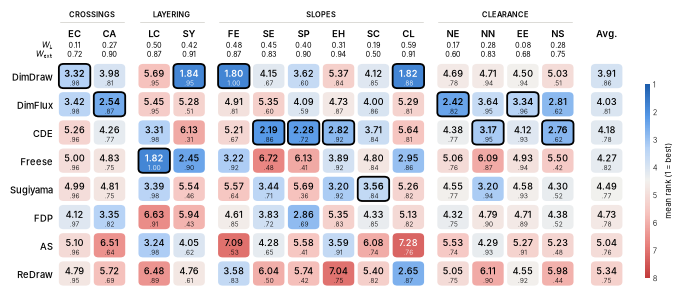

In [4]:
def rank_heatmap(fname):
    '''Mean rank (tile colour, large) and mean score (small) per algorithm x metric; outline = best mean rank.'''
    INK = '#000000'
    cmap = LinearSegmentedColormap.from_list('div2', ['#1c5cab', '#5598e7', '#b7d3f6', '#f2f1ee',
                                                      '#f6c4bf', '#e8807c', '#c23b3b'])
    norm = Normalize(vmin=1, vmax=K)
    order = avg_rank.sort_values().index
    xs, x, prev = {}, 0.0, None          # metrics with a gap between families, then a wider gap before Avg.
    for m in MS:
        if prev and FAMILY[m] != FAMILY[prev]: x += 0.28
        xs[m] = x; x += 1; prev = m
    xs['Avg.'] = x + 0.4
    cols = MS + ['Avg.']
    with mpl.rc_context({'font.family': 'Inter', 'font.size': 6.5, 'mathtext.fontset': 'custom',
                         'mathtext.rm': 'Inter', 'mathtext.it': 'Inter:italic', 'mathtext.bf': 'Inter:bold'}):
        fig, ax = plt.subplots(figsize=(TEXT_W, 2.85))
        w, h, pad = 0.9, 0.86, 0.08
        box = lambda m, i, **kw: FancyBboxPatch((xs[m] - w / 2 + pad, i - h / 2 + pad), w - 2 * pad, h - 2 * pad,
                                                boxstyle=f'round,pad={pad},rounding_size=0.14', **kw)
        for i, a in enumerate(order):
            for m in cols:
                r = avg_rank[a] if m == 'Avg.' else mean_rank.loc[a, m]
                s = avg_score[a] if m == 'Avg.' else mean_score.loc[a, m]
                best = m != 'Avg.' and a == leader[m]
                ax.add_patch(box(m, i, lw=0, fc=cmap(norm(r))))
                if best: ax.add_patch(box(m, i, lw=1.3, fc='none', ec=INK))
                ink = 'white' if abs(r - (K + 1) / 2) > 2.6 else INK
                ax.text(xs[m], i - 0.13, f'{r:.2f}', ha='center', va='center_baseline',
                        fontsize=6.6, color=ink, fontweight='semibold' if best else 'medium')
                ax.text(xs[m], i + 0.22, f'{s:.2f}'.replace('0.', '.', 1) if s < 0.995 else '1.00',
                        ha='center', va='center_baseline', fontsize=4.8, color=ink, fontweight=300)
        for f in FAMILIES:
            ms = FAM_OF[f]; x0, x1 = xs[ms[0]] - 0.42, xs[ms[-1]] + 0.42
            ax.text((x0 + x1) / 2, -2.02, f.upper(), ha='center', va='bottom', fontsize=5.4, color=INK,
                    fontweight='semibold')
            ax.plot([x0, x1], [-1.9, -1.9], color='#d6d5d0', lw=0.6, solid_capstyle='round')
        for m in cols:
            ax.text(xs[m], -1.38, m, ha='center', va='baseline', fontsize=6.8, color=INK, fontweight='semibold')
            if m in MS:
                ax.text(xs[m], -1.0, f'{friedman.loc[m, "W_L"]:.2f}', ha='center', va='baseline', fontsize=5.2, color=INK)
                ax.text(xs[m], -0.68, f'{w_cxt[m]:.2f}', ha='center', va='baseline', fontsize=5.2, color=INK)
        ax.text(-0.62, -1.0, '$W_L$', ha='right', va='baseline', fontsize=5.6, color=INK)
        ax.text(-0.62, -0.68, r'$W_{\mathrm{cxt}}$', ha='right', va='baseline', fontsize=5.6, color=INK)
        for i, a in enumerate(order):
            ax.text(-0.62, i, a, ha='right', va='center_baseline', fontsize=6.8, color=INK, fontweight='medium')
        ax.set_xlim(-0.6, xs['Avg.'] + 0.5); ax.set_ylim(K - 0.45, -2.15); ax.axis('off')
        cax = fig.add_axes([0.93, 0.06, 0.007, 0.68])
        cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, ticks=range(1, K + 1))
        cb.outline.set_visible(False); cb.ax.invert_yaxis()
        cb.ax.tick_params(length=0, labelsize=5.4, colors=INK, pad=2)
        for lb in cb.ax.get_yticklabels(): lb.set_fontweight(300)
        cb.set_label('mean rank (1 = best)', fontsize=5.6, color=INK, labelpad=4)
        fig.subplots_adjust(left=0.085, right=0.9, top=0.98, bottom=0.02)
        for ext in ('pdf', 'png'):
            fig.savefig(FIG / f'{fname}.{ext}', bbox_inches='tight', pad_inches=0.02)

rank_heatmap('ranks')

## Context types (Table `tab:context`)

Mean ranks per context type, averaged within each metric family and then equally across families.

In [5]:
print('metrics with W_cxt >= 0.8:', int((w_cxt >= 0.8).sum()), 'of', len(MS))
print('lowest W_cxt:', w_cxt.nsmallest(3).round(2).to_dict())

fam_cxt = pd.DataFrame({d: fam_avg(rank_cxt[d]) for d in DS}).loc[AL]
n_cxt = pd.Series(cat).value_counts().reindex(DS)
display(fam_cxt.loc[avg_rank.sort_values().index].round(2))
print('best per context type:', fam_cxt.idxmin().to_dict())
print('N:', n_cxt.to_dict())
print('median |L|:', P.groupby('dataset').n_concepts.median().reindex(DS).to_dict())

lines = [r'\begin{tabular}{l' + 'r' * len(DS) + '}', r'\toprule', ' & '.join(['Algorithm'] + DS) + r' \\', r'\midrule']
for a in avg_rank.sort_values().index:
    cells = [(r'\textbf{%.2f}' if fam_cxt.loc[a, d] <= fam_cxt[d].min() + 1e-9 else '%.2f') % fam_cxt.loc[a, d] for d in DS]
    lines.append(' & '.join([a] + cells) + r' \\')
lines += [r'\midrule', ' & '.join([r'$N$'] + [str(n) for n in n_cxt]) + r' \\', r'\bottomrule', r'\end{tabular}']
_ = (TAB / 'context.tex').write_text('\n'.join(lines) + '\n')

metrics with W_cxt >= 0.8: 9 of 14
lowest W_cxt: {'SC': 0.5, 'NE': 0.6, 'EE': 0.68}


,M4,Random,Real-world,Theory
algorithm,,,,
DimDraw,4.32,3.71,3.81,3.79
DimFlux,4.60,3.84,3.85,3.84
CDE,3.99,4.28,4.24,4.21
Freese,4.16,4.24,4.25,4.41
Sugiyama,4.23,4.76,4.32,4.66
FDP,4.78,4.67,5.03,4.44
AS,4.75,5.26,5.23,4.95
ReDraw,5.17,5.24,5.28,5.70


best per context type: {'M4': 'CDE', 'Random': 'DimDraw', 'Real-world': 'DimDraw', 'Theory': 'DimDraw'}
N: {'M4': 126, 'Random': 42, 'Real-world': 34, 'Theory': 18}
median |L|: {'M4': 9.0, 'Random': 18.0, 'Real-world': 19.0, 'Theory': 22.0}


## Lattice size

Relative effect: OLS of goodness $= 9 - \text{rank}$ on standardised $\log_2|L|$ with context-type fixed effects,
HC3 standard errors, BH correction over all $8 \times 14$ tests. $\beta$ = rank positions gained per SD of $\log_2|L|$.

In [6]:
z = ((P.log2_n - P.log2_n.mean()) / P.log2_n.std()).values
D = pd.get_dummies(P.dataset).reindex(columns=DS).astype(float).values[:, 1:]
size_eff = pd.DataFrame([(m, a, *ols_hc3((K + 1) - ranks[m][a].values, np.column_stack([np.ones(N), z, D])))
                         for m in MS for a in AL], columns=['metric', 'alg', 'beta', 'p'])
size_eff['q'] = bh(size_eff.p)
show = size_eff[size_eff.metric.isin(['SC', 'FE'])].pivot(index='alg', columns='metric', values=['beta', 'q'])
display(show.round(3))

n = P.n_concepts.values
ns_size = pd.DataFrame({'|L| <= 20': wide['NS'][n <= 20].mean(), '|L| > 20': wide['NS'][n > 20].mean(),
                        '|L| > 40': wide['NS'][n > 40].mean()})
display(ns_size.sort_values('|L| <= 20', ascending=False).round(2))
print('max mean NS:', ns_size.max().round(2).to_dict())

beta             q       
metric       FE     SC     FE     SC
alg                                 
AS       -0.581 -1.189  0.000  0.000
CDE      -0.672 -1.412  0.000  0.000
DimDraw   0.693  1.341  0.000  0.000
DimFlux   0.441  0.155  0.001  0.341
FDP       1.392  1.349  0.000  0.000
Freese    0.130  0.685  0.139  0.000
ReDraw   -0.459  0.588  0.001  0.000
Sugiyama -0.944 -1.516  0.000  0.000

,|L| <= 20,|L| > 20,|L| > 40
algorithm,,,
DimFlux,0.83,0.28,0.08
CDE,0.82,0.30,0.15
FDP,0.77,0.18,0.04
Sugiyama,0.74,0.14,0.06
DimDraw,0.70,0.22,0.06
AS,0.67,0.16,0.06
ReDraw,0.66,0.09,0.01
Freese,0.63,0.11,0.03


max mean NS: {'|L| <= 20': 0.83, '|L| > 20': 0.3, '|L| > 40': 0.15}


## Distributivity (Figure `distributivity`)

* **Absolute:** partial Spearman of the score (averaged over algorithms) with the distributivity degree,
  on non-distributive lattices only, controlling for $\log_2|L|$.
* **Relative:** rank regressions as above, with (a) the distributivity degree (standardised, non-distributive lattices)
  and (b) the indicator *distributive* (all lattices) as predictor.

In [7]:
nd = ~P.distributive.values
absd = pd.DataFrame([(m, *partial_spearman(P.distributivity_degree.values[nd], wide[m].mean(axis=1).values[nd],
                                           P.log2_n.values[nd])) for m in MS], columns=['metric', 'rho', 'p'])
absd['q'] = bh(absd.p)
display(absd.sort_values('rho', ascending=False).round(3))

Xd = np.column_stack([np.ones(N), P.distributive.values.astype(float), z, D])
deg = (P.distributivity_degree - P.distributivity_degree[nd].mean()) / P.distributivity_degree[nd].std()
Xc = np.column_stack([np.ones(nd.sum()), deg.values[nd], z[nd], D[nd]])
rows = []
for m in MS:
    for a in AL:
        g = (K + 1) - ranks[m][a].values
        rows.append((m, a, *ols_hc3(g[nd], Xc), *ols_hc3(g, Xd)))
rel = pd.DataFrame(rows, columns=['metric', 'alg', 'b_degree', 'p_degree', 'b_distr', 'p_distr'])
rel['q_degree'] = bh(rel.p_degree); rel['q_distr'] = bh(rel.p_distr)
print(f'max |shift| per SD of distributivity degree: {rel.b_degree.abs().max():.2f}')
print('largest effects of exact distributivity (FDR 5 %):')
display(rel[rel.q_distr < ALPHA].assign(abs_=rel.b_distr.abs()).nlargest(8, 'abs_')
        [['metric', 'alg', 'b_distr', 'q_distr']].round(3))

,metric,rho,p,q
6,SP,0.822,0.000,0.000
4,FE,0.712,0.000,0.000
2,LC,0.605,0.000,0.000
8,SC,0.584,0.000,0.000
10,NE,0.565,0.000,0.000
13,NS,0.523,0.000,0.000
11,NN,0.405,0.000,0.000
9,CL,0.369,0.000,0.000
1,CA,0.341,0.000,0.000
7,EH,0.326,0.000,0.000


max |shift| per SD of distributivity degree: 0.69
largest effects of exact distributivity (FDR 5 %):


,metric,alg,b_distr,q_distr
47,SE,Sugiyama,-2.828,0.0
43,SE,DimFlux,2.433,0.0
18,LC,DimDraw,-2.057,0.0
105,NS,CDE,1.647,0.0
55,SP,Sugiyama,-1.633,0.0
51,SP,DimFlux,1.551,0.0
61,EH,Freese,-1.430,0.0
66,SC,DimDraw,-1.375,0.0


In [8]:
# Figure: absolute score (top) and mean rank (bottom) by distributivity-degree bin
BINS = [0, 0.85, 0.92, 0.97, 1.0]
BLAB = ['<.85', '.85–.92', '.92–.97', '.97–1', 'distr.']
bin_lab = pd.Series(pd.cut(P.distributivity_degree, BINS, labels=BLAB[:-1]).astype(object).values, index=keys)
bin_lab[P.distributive.values] = 'distr.'
print(bin_lab.value_counts().reindex(BLAB).to_dict())

SHOW = ['LC', 'SE', 'NS']
INK, MUTED = '#000000', '#4a4a46'
COL_W = 3.33   # inches: one column
with mpl.rc_context({'font.family': 'Inter', 'font.size': 7, 'axes.edgecolor': '#b5b4ae',
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': INK,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'axes.labelsize': 7.5}):
    fig, axes = plt.subplots(2, 3, figsize=(COL_W, 2.5), sharex=True)
    x = np.arange(len(BLAB))
    for j, m in enumerate(SHOW):
        for a in AL:
            s = wide[m][a].groupby(bin_lab.values).mean().reindex(BLAB)
            rk = ranks[m][a].groupby(bin_lab.values).mean().reindex(BLAB)
            mk = dict(marker=MARKER[a], ms=3.2, mew=0)
            for row, v in [(0, s), (1, rk)]:
                ax = axes[row, j]
                ax.plot(x[:-1], v.values[:-1], color=COLOR[a], lw=0.9, label=a, **mk)
                ax.plot(x[-2:], v.values[-2:], color=COLOR[a], lw=0.7, ls=(0, (1, 1.5)))
                ax.plot(x[-1], v.values[-1], color=COLOR[a], ls='none', **mk)
        axes[0, j].set_title(m, fontsize=8, fontweight='semibold', color=INK, pad=4)
        axes[0, j].yaxis.set_major_locator(mpl.ticker.MaxNLocator(3, steps=[1, 2, 5, 10]))
        axes[1, j].set_yticks([2, 4, 6]); axes[1, j].set_ylim(7.7, 1.1)
        for ax in axes[:, j]:
            ax.axvspan(len(BLAB) - 1.5, len(BLAB) - 0.5, color='#f2f1ee', lw=0, zorder=0)
            ax.grid(axis='y'); ax.set_axisbelow(True)
            ax.tick_params(length=2, width=0.5, pad=1)
            ax.spines['left'].set_linewidth(0.5); ax.spines['bottom'].set_linewidth(0.5)
        axes[1, j].set_xticks(x, BLAB, rotation=55, ha='right', rotation_mode='anchor')
        axes[1, j].set_xlim(-0.3, len(BLAB) - 0.5)
    axes[0, 0].set_ylabel('score'); axes[1, 0].set_ylabel('rank')
    fig.align_ylabels(axes[:, 0])
    fig.tight_layout(h_pad=0.3, w_pad=0.0, pad=0.15, rect=(0, 0.17, 1, 1))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False,
               bbox_to_anchor=(0.5, 0), borderaxespad=0, columnspacing=1.2,
               handlelength=1.6, handletextpad=0.4, labelspacing=0.3, fontsize=mpl.rcParams['axes.labelsize'])
    save(fig, 'distributivity')

{'<.85': 27, '.85–.92': 52, '.92–.97': 72, '.97–1': 30, 'distr.': 39}


## Gradedness and layer consistency

Layered algorithms place $v$ on its longest-path layer $h(v)$; $\mathrm{LC}$ compares with $\rho(v) = h(v) - d(v) + M$.
Both coincide for every node iff every element lies on a maximum-length chain, i.e. iff the lattice is graded.

In [9]:
def chain_structure(dataset, lattice):
    '''(graded, share of elements not on a maximum-length chain), from the cover graph.'''
    G = nx.transitive_reduction(nx.DiGraph(load_layout(str(ROOT / 'graphml' / 'freese' / dataset / f'{lattice}.graphml')).graph))
    order = list(nx.topological_sort(G)); h = dict.fromkeys(order, 0); d = dict.fromkeys(order, 0)
    for v in order:
        for w in G.successors(v): h[w] = max(h[w], h[v] + 1)
    for v in reversed(order):
        for w in G.successors(v): d[v] = max(d[v], d[w] + 1)
    M = max(h.values())
    return all(h[w] == h[v] + 1 for v, w in G.edges()), np.mean([h[v] + d[v] < M for v in order])

cs = [chain_structure(P.loc[k, 'raw_dataset'], P.loc[k, 'lattice']) for k in keys]
P['graded'] = [c[0] for c in cs]; P['off_rank'] = [c[1] for c in cs]
assert P.loc[P.modular, 'graded'].all()
g = P.graded.values
print('graded:', int(g.sum()), '| graded non-modular:', int((g & ~P.modular.values).sum()))

perfect_lc = wide['LC'] >= 1 - 1e-9
display(pd.DataFrame({'graded': perfect_lc[g].mean(), 'not graded': perfect_lc[~g].mean()}).round(3))

ng = ~g
r_off = partial_spearman(P.distributivity_degree.values[ng], P.off_rank.values[ng], P.log2_n.values[ng])
off_bins = P.off_rank[ng].groupby(bin_lab[ng]).mean().reindex(BLAB[:-1])
print('off-rank share by distributivity bin (non-graded):', off_bins.round(2).to_dict())
print(f'partial Spearman rho = {r_off.statistic:.2f} (p = {r_off.pvalue:.3f})')

graded: 96 | graded non-modular: 47


,graded,not graded
algorithm,,
AS,1.000,0.048
CDE,1.000,0.000
DimDraw,0.073,0.008
DimFlux,0.062,0.000
FDP,0.031,0.000
Freese,1.000,1.000
ReDraw,0.000,0.000
Sugiyama,1.000,0.000


off-rank share by distributivity bin (non-graded): {'<.85': 0.38, '.85–.92': 0.25, '.92–.97': 0.23, '.97–1': 0.19}
partial Spearman rho = -0.21 (p = 0.018)
